# Visualizing features from local linearization of neural nets

In [ ]:
!pip install ipympl torchviz
!pip install torch

In [2]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import copy
import time
from torchvision.models.feature_extraction import create_feature_extractor
from ipywidgets import fixed, interactive, widgets
%matplotlib inline

In [3]:
def to_torch(x):
    return torch.from_numpy(x).float()


def to_numpy(x):
    return x.detach().cpu().numpy()


def plot_data(X, y, X_test, y_test):
    clip_bound = 2.5
    plt.xlim(0, 1)
    plt.ylim(-clip_bound, clip_bound)
    plt.scatter(X[:, 0], y, c='darkorange', s=40.0, label='training data points')
    plt.plot(X_test, y_test, '--', color='royalblue', linewidth=2.0, label='Ground truth')


def plot_relu(bias, slope):
    plt.scatter([-bias / slope], 0, c='darkgrey', s=40.0)
    if slope > 0 and bias < 0:
        plt.plot([0, -bias / slope, 1], [0, 0, slope * (1 - bias)], ':')
    elif slope < 0 and bias > 0:
        plt.plot([0, -bias / slope, 1], [-bias * slope, 0, 0], ':')


def plot_relus(params):
    slopes = to_numpy(params[0]).ravel()
    biases = to_numpy(params[1])
    for relu in range(biases.size):
        plot_relu(biases[relu], slopes[relu])


def plot_function(X_test, net):
    y_pred = net(to_torch(X_test))
    plt.plot(X_test, to_numpy(y_pred), '-', color='forestgreen', label='prediction')


def plot_update(X, y, X_test, y_test, net, state=None):
    if state is not None:
        net.load_state_dict(state)
    plt.figure(figsize=(10, 7))
    plot_relus(list(net.parameters()))
    plot_function(X_test, net)
    plot_data(X, y, X_test, y_test)
    plt.legend()
    plt.show();


def train_network(X, y, X_test, y_test, net, optim, n_steps, save_every, device="cpu", initial_weights=None, verbose=False):
    loss = torch.nn.MSELoss()
    y_train = to_torch(y.reshape(-1, 1)).to(device=device)
    X_train = to_torch(X).to(device=device)

    y_test = to_torch(y_test.reshape(-1, 1)).to(device=device)
    X_test = to_torch(X_test).to(device=device)
    if initial_weights is not None:
        net.load_state_dict(initial_weights)
    history = {}
    for s in range(n_steps):
        perm = torch.randperm(y.size, device=device)
        subsample = perm[:y.size // 5]
        step_loss = loss(y_train[subsample], net(X_train[subsample, :]))
        optim.zero_grad()
        step_loss.backward()
        optim.step()
        if (s + 1) % save_every == 0 or s == 0:
            history[s + 1] = {}
            history[s + 1]['state'] = copy.deepcopy(net.state_dict())
            with torch.no_grad():
                test_loss = loss(y_test, net(X_test))
            history[s + 1]['train_error'] = to_numpy(step_loss).item()
            history[s + 1]['test_error'] = to_numpy(test_loss).item()
            if verbose:
                print("SGD Iteration %d" % (s + 1))
                print("\tTrain Loss: %.3f" % to_numpy(step_loss).item())
                print("\tTest Loss: %.3f" % to_numpy(test_loss).item())
            else:
                # Print update every 10th save point
                if (s + 1) % (save_every * 10) == 0:
                    print("SGD Iteration %d" % (s + 1))

    return history


def plot_test_train_errors(history):
    sample_points = np.array(list(history.keys()))
    etrain = [history[s]['train_error'] for s in history]
    etest = [history[s]['test_error'] for s in history]
    plt.plot(sample_points / 1e3, etrain, label='Train Error')
    plt.plot(sample_points / 1e3, etest, label='Test Error')
    plt.xlabel("Iterations (1000's)")
    plt.ylabel("MSE")
    plt.yscale('log')
    plt.legend()
    plt.show();


def make_iter_slider(iters):
    return widgets.SelectionSlider(
        options=iters,
        value=1,
        description='SGD Iterations: ',
        disabled=False
    )


def history_interactive(history, idx, X, y, X_test, y_test, net):
    plot_update(X, y, X_test, y_test, net, state=history[idx]['state'])
    plt.show()
    print("Train Error: %.3f" % history[idx]['train_error'])
    print("Test Error: %.3f" % history[idx]['test_error'])


def make_history_interactive(history, X, y, X_test, y_test, net):
    sample_points = list(history.keys())
    return interactive(history_interactive,
                       history=fixed(history),
                       idx=make_iter_slider(sample_points),
                       X=fixed(X),
                       y=fixed(y),
                       X_test=fixed(X_test),
                       y_test=fixed(y_test),
                       net=fixed(net))


%matplotlib inline

# Generate Training and Test Data

We are using piecewise linear function. Our training data has added noise $y = f(x) + \epsilon,\, \epsilon \sim \mathcal{N}(0, \sigma^2)$. The test data is noise free.

_Once you have gone through the discussion once you may wish to adjust the number of training samples and noise variance to see how gradient descent behaves under the new conditions._

In [4]:
f_type = 'piecewise_linear'

def f_true(X, f_type):
    if f_type == 'sin(20x)':
        return np.sin(20 * X[:,0])
    else:
        TenX = 10 * X[:,0]
        _ = 12345
        return (TenX - np.floor(TenX)) * np.sin(_ * np.ceil(TenX)) - (TenX - np.ceil(TenX)) * np.sin(_ * np.floor(TenX))

n_features = 1
n_samples = 200
sigma = 0.1
rng = np.random.RandomState(1)

# Generate train data
X = np.sort(rng.rand(n_samples, n_features), axis=0)
y = f_true(X, f_type) + rng.randn(n_samples) * sigma

# Generate NOISELESS test data
X_test = np.concatenate([X.copy(), np.expand_dims(np.linspace(0., 1., 1000), axis=1)])
X_test = np.sort(X_test, axis=0)
y_test = f_true(X_test, f_type)

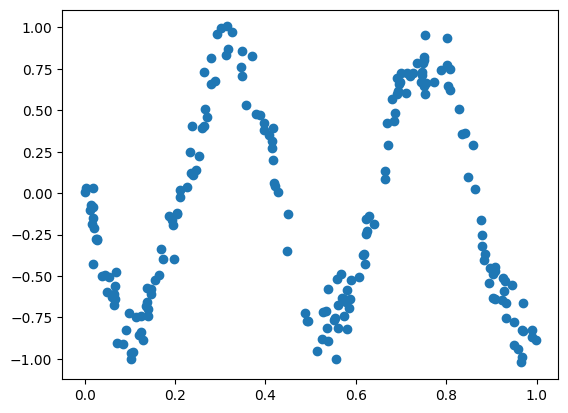

In [5]:
plt.scatter(X, y)
plt.show()

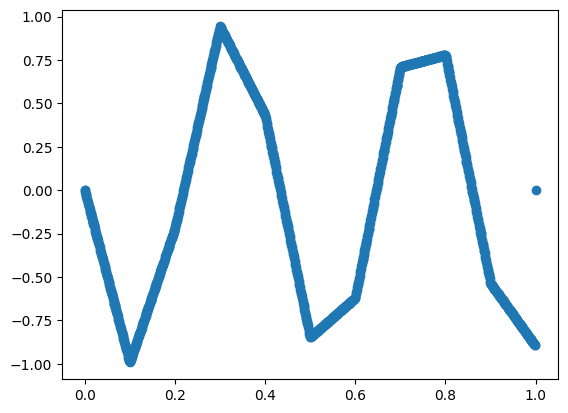

In [6]:
plt.scatter(X_test, y_test)
plt.show()

# Define the Neural Networks

We will learn the piecewise linear target function using a simple 1-hidden layer neural network with ReLU non-linearity, defined by
$$ \hat{y} = \mathbf{W}^{(2)} \Phi \left( \mathbf{W}^{(1)} x + \mathbf{b}^{(1)} \right) + \mathbf{b}^{(2)} $$
where $\Phi(x) = ReLU(x)$ and superscripts refer to indices, not the power operator.

We will also create two SGD optimizers to allow us to choose whether to train all parameters or only the linear output layer's parameters. Note that we use separate learning rates for the two version of training. There is too much variance in the gradients when training all layers to use a large learning rate, so we have to decrease it.

We will modify the default initialization of the biases so that the ReLU elbows are all inside the region we are interested in.

We create several versions of this network with varying widths to explore how hidden layer width impacts learning performance.

_Once you have gone through the discussion once you may wish to train networks with even larger widths to see how they behave under the three different training paradigms in this notebook._

In [7]:
# Don't rerun this cell after training or you will lose all your work
nets_by_size = {}

In [8]:
widths = [10, 20, 40]
for width in widths:
    # Define a 1-hidden layer ReLU nonlinearity network
    net = nn.Sequential(nn.Linear(1, width),
                        nn.ReLU(),
                        nn.Linear(width, 1))
    loss = nn.MSELoss()
    # Get trainable parameters
    weights_all = list(net.parameters())
    # Get the output weights alone
    weights_out = weights_all[2:]
    # Adjust initial biases so elbows are in [0,1]
    elbows = np.sort(np.random.rand(width))
    new_biases = -elbows * to_numpy(weights_all[0]).ravel()
    weights_all[1].data = to_torch(new_biases)
    # Create SGD optimizers for outputs alone and for all weights
    lr_out = 0.2
    lr_all = 0.02
    opt_all = torch.optim.SGD(params=weights_all, lr=lr_all)
    opt_out = torch.optim.SGD(params=weights_out, lr=lr_out)
    # Save initial state for comparisons
    initial_weights = copy.deepcopy(net.state_dict())
    # print("Initial Weights", initial_weights)
    nets_by_size[width] = {'net': net, 'opt_all': opt_all,
                           'opt_out': opt_out, 'init': initial_weights}

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
for width, net in nets_by_size.items():
  net['net'].to(device=device)

# Train the neural networks

----------------------------------------
Width 10
SGD Iteration 10000
SGD Iteration 20000
SGD Iteration 30000
SGD Iteration 40000
SGD Iteration 50000
SGD Iteration 60000
SGD Iteration 70000
SGD Iteration 80000
SGD Iteration 90000
SGD Iteration 100000
SGD Iteration 110000
SGD Iteration 120000
SGD Iteration 130000
SGD Iteration 140000
SGD Iteration 150000
Width 10


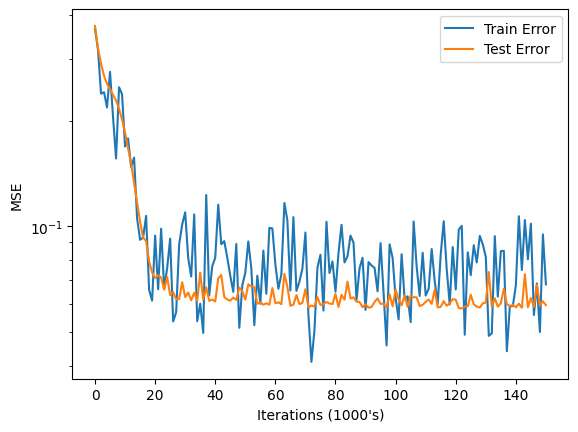

----------------------------------------
Width 20
SGD Iteration 10000
SGD Iteration 20000
SGD Iteration 30000
SGD Iteration 40000
SGD Iteration 50000
SGD Iteration 60000
SGD Iteration 70000
SGD Iteration 80000
SGD Iteration 90000
SGD Iteration 100000
SGD Iteration 110000
SGD Iteration 120000
SGD Iteration 130000
SGD Iteration 140000
SGD Iteration 150000
Width 20


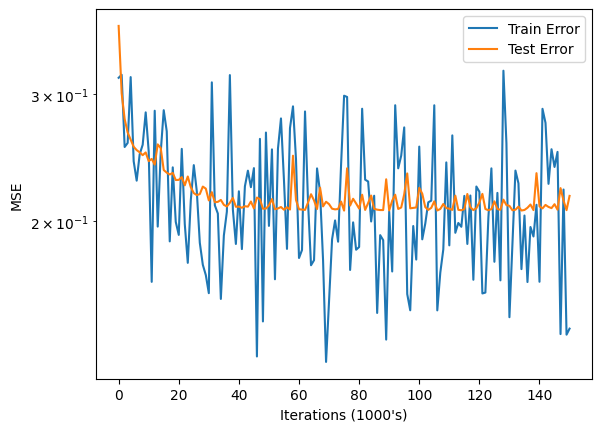

----------------------------------------
Width 40
SGD Iteration 10000
SGD Iteration 20000
SGD Iteration 30000
SGD Iteration 40000
SGD Iteration 50000
SGD Iteration 60000
SGD Iteration 70000
SGD Iteration 80000
SGD Iteration 90000
SGD Iteration 100000
SGD Iteration 110000
SGD Iteration 120000
SGD Iteration 130000
SGD Iteration 140000
SGD Iteration 150000
Width 40


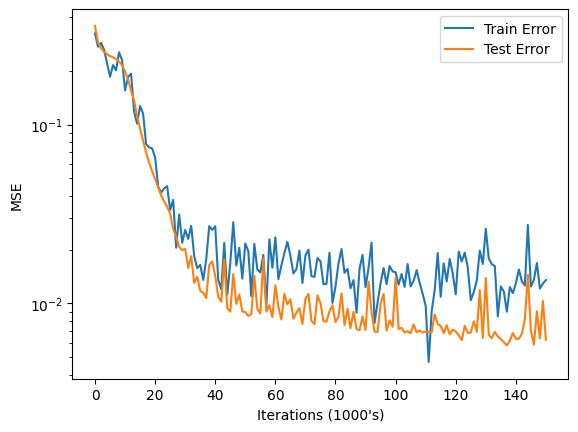

----------------------------------------
Trained all layers in 7.8 minutes


In [10]:
n_steps = 150000
save_every = 1000
t0 = time.time()
for w in widths:
    print("-"*40)
    print("Width", w)
    new_net = nn.Sequential(nn.Linear(1, w),
                        nn.ReLU(),
                        nn.Linear(w, 1))
    new_net.load_state_dict(nets_by_size[w]['net'].state_dict().copy())
    new_net.to(device=device)
    opt_all = torch.optim.SGD(params=new_net.parameters(), lr=lr_all)
    initial_weights = nets_by_size[w]['init']
    history_all = train_network(X, y, X_test, y_test,
                            new_net, optim=opt_all,
                            n_steps=n_steps, save_every=save_every,
                            initial_weights=initial_weights,
                            verbose=False, device=device)
    nets_by_size[w]['trained_net'] = new_net
    nets_by_size[w]['hist_all'] = history_all
    print("Width", w)
    plot_test_train_errors(history_all)
t1 = time.time()
print("-"*40)
print("Trained all layers in %.1f minutes" % ((t1 - t0) / 60))

# (a) Visualize Gradients

Visualize the features corresponding to
$\frac{\partial}{\partial w_i^{(1)}} y(x)$
and
$\frac{\partial}{\partial b_i^{(1)}} y(x)$
where
$w^{(1)}_i$
are
the first hidden layer's weights and the
$b^{(1)}_i$
are the first hidden layer's biases. These derivatives should be evaluated at
at least both the random initialization and the final trained
network. When visualizing these features, plot them as a function
of the scalar input $x$, the same way that the notebook plots the
constituent "elbow" features that are the outputs of the
penultimate layer.

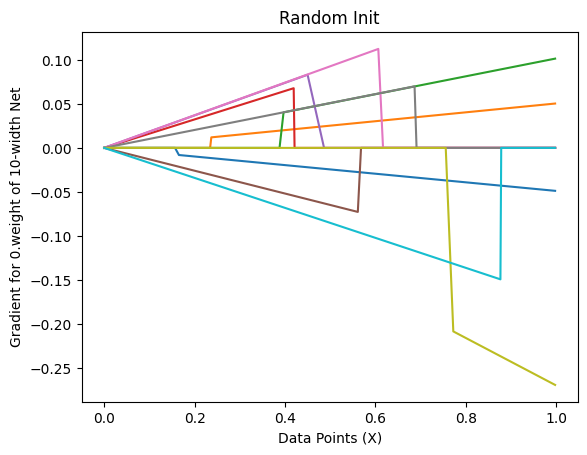

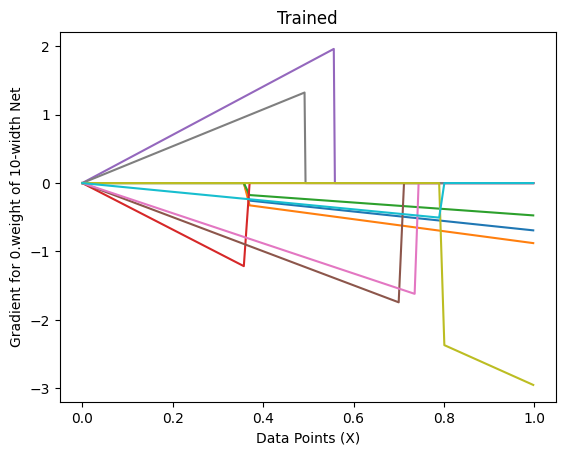

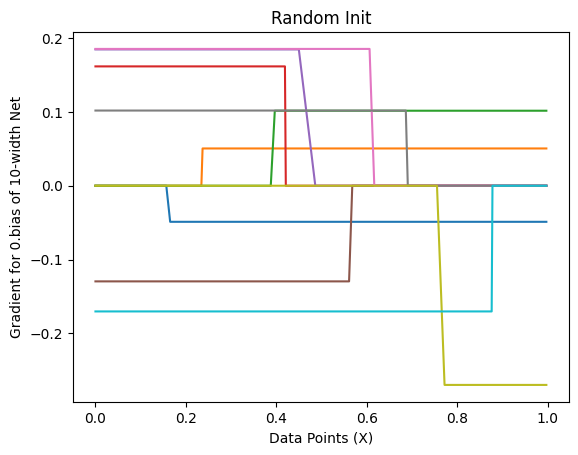

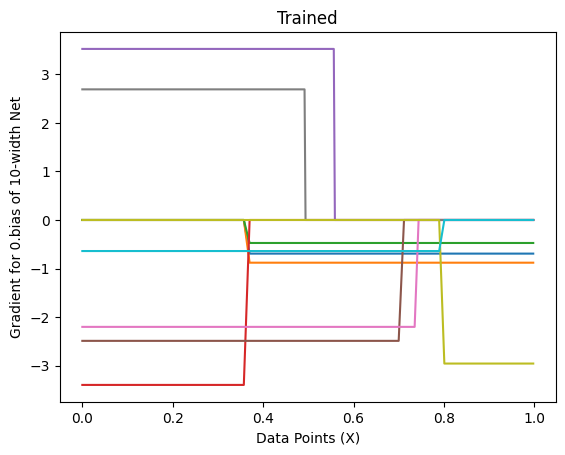

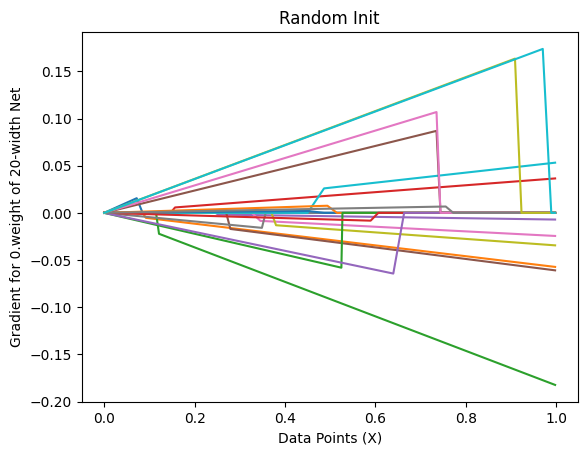

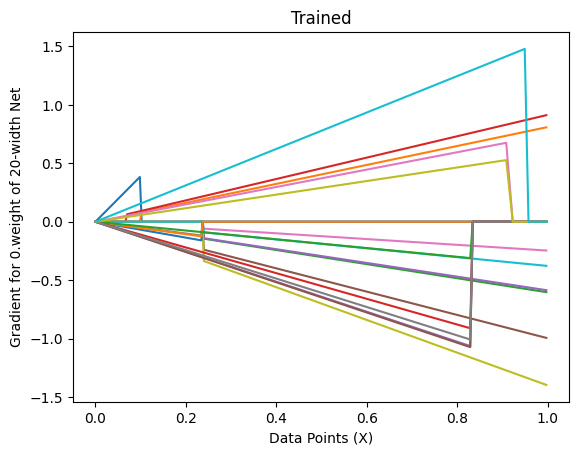

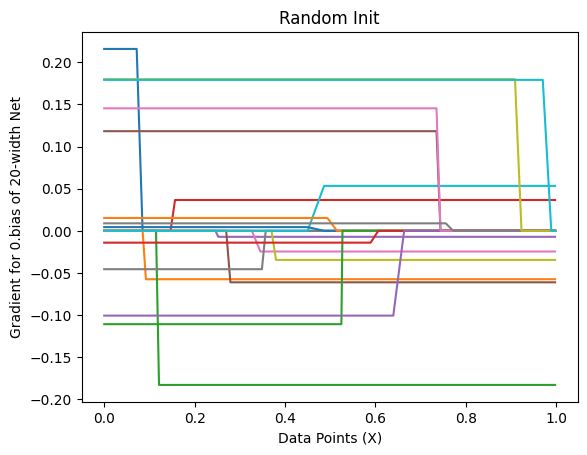

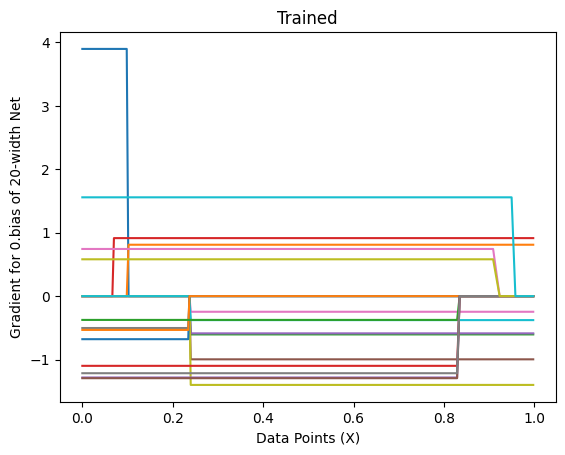

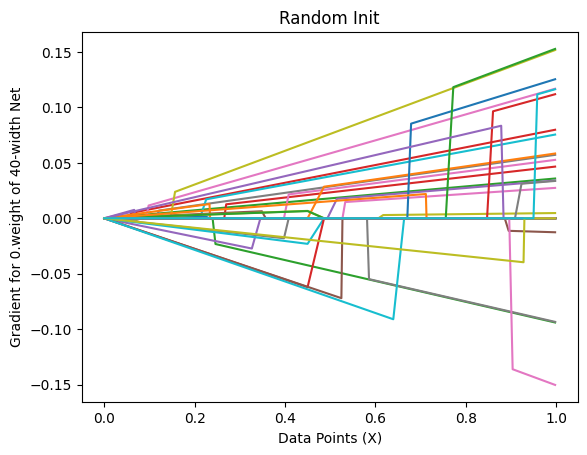

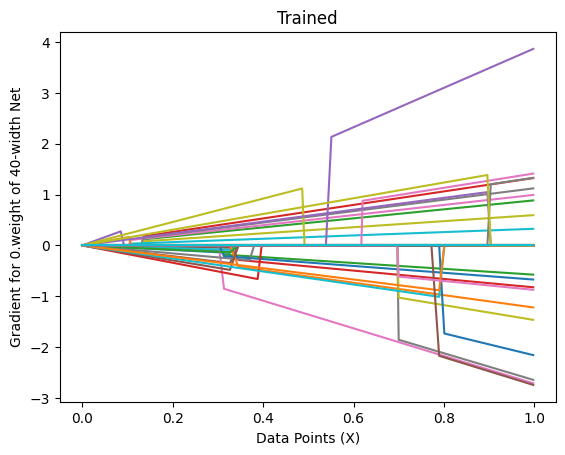

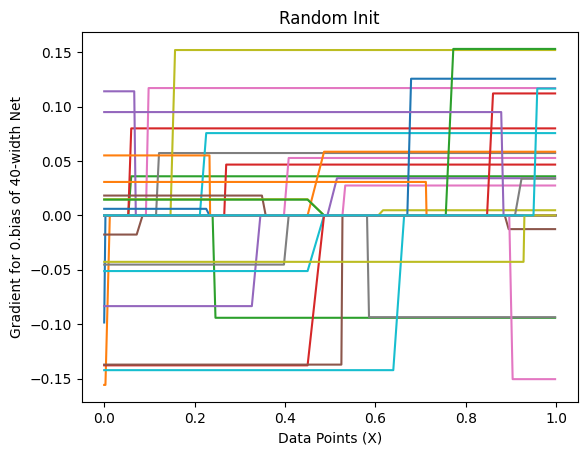

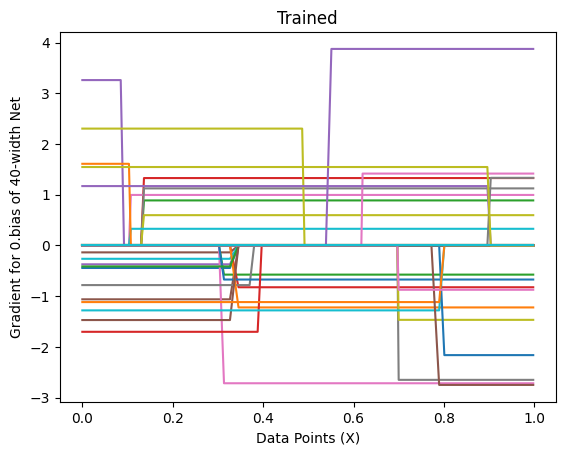

In [11]:
def backward_and_plot_grad(X, model, vis_name='all', title='', legend=False):
    """
    Run backpropagation on `model` using `X` as the input
    to compute the gradient w.r.t. parameters of `y`,
    and then visualize collected gradients according to `vis_name`
    """
    width = model[0].out_features  # the width is the number of hidden units.
    gradients = np.zeros((width, X.shape[0]))
    num_pts = 0
    gradient_collect, vis_collect = { }, { }
    for x in X:
        y = model(to_torch(x).to(device=device))

        ########################################################################
        # TODO: Complete the following part to run backpropagation. (2 lines)
        # Hint: Remember to set grad to zero before backpropagation
        ########################################################################
        model.zero_grad()
        y.backward()
        ########################################################################

        # collect gradients from `p.grad.data`
        for n, p in model.named_parameters():
            for w_idx, w_grad in enumerate( p.grad.data.reshape(-1) ):
                if f'{n}.{w_idx}' not in gradient_collect:
                    gradient_collect[ f'{n}.{w_idx}' ] = {'x':[], 'y': []}
                if vis_name == 'all' or vis_name == n:
                    if f'{n}.{w_idx}' not in vis_collect:
                        vis_collect[f'{n}.{w_idx}'] = True
                gradient_collect[ f'{n}.{w_idx}' ]['y'].append( w_grad.item() )
                gradient_collect[ f'{n}.{w_idx}' ]['x'].append( x )

    for w_n in vis_collect:
        # we assume that X is sorted, so we use line plot
        plt.plot( X, gradient_collect[w_n]['y'], label=w_n )

    plt.xlabel('Data Points (X)')
    plt.ylabel(f'Gradient for {vis_name} of {width}-width Net')
    if legend:
        plt.legend()
    plt.title(title)
    plt.show()


for width in nets_by_size:
    backward_and_plot_grad(X, nets_by_size[width]['net'], '0.weight', 'Random Init')
    backward_and_plot_grad(X, nets_by_size[width]['trained_net'], '0.weight', 'Trained')
    backward_and_plot_grad(X, nets_by_size[width]['net'], '0.bias', 'Random Init')
    backward_and_plot_grad(X, nets_by_size[width]['trained_net'], '0.bias', 'Trained')

# (b) SVD for feature matrix

During training, we can imagine that we have a generalized
linear model with a feature matrix corresponding to the linearized
features corresponding to each learnable parameter. We know from
our analysis of gradient descent, that the singular values and
singular vectors corresponding to this feature matrix are
important.

Use the SVD of this feature matrix to plot both the singular values and visualize the “principle
features” that correspond to the d-dimensional singular vectors multiplied by all the features
corresponding to the parameters

(HINT: Remember that the feature matrix whose SVD you are
taking has $n$ rows where each row corresponds to one training
point and $d$ columns where each column corresponds to each of
the learnable features. Meanwhile, you are going to be
plotting/visualizing the "principle features" as functions of
$x$ even at places where you don't have training points.)

Width 10


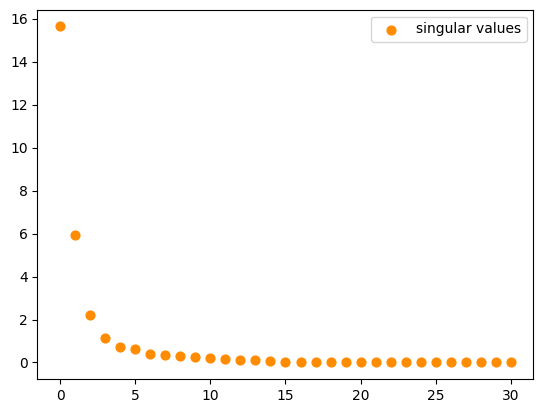

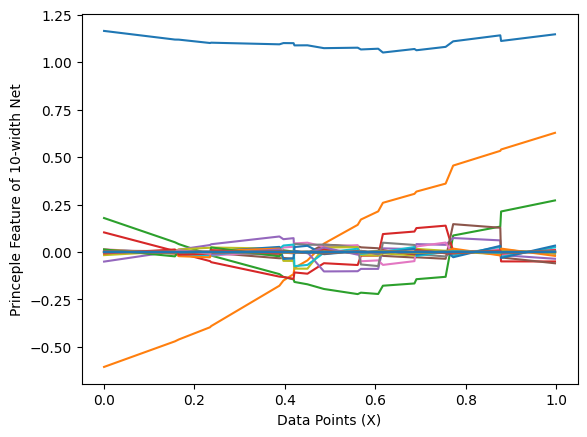

Width 20


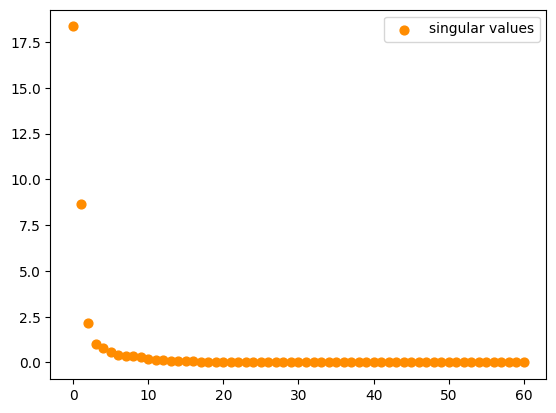

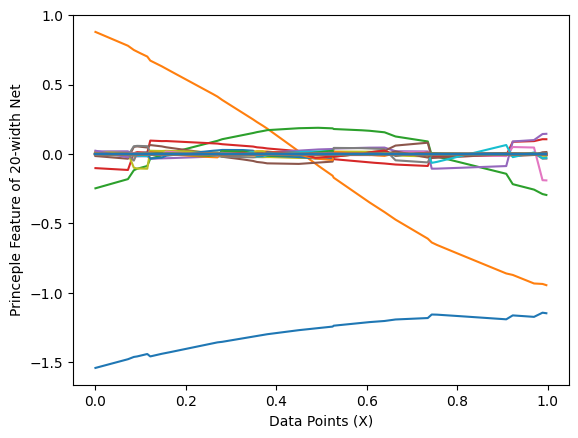

Width 40


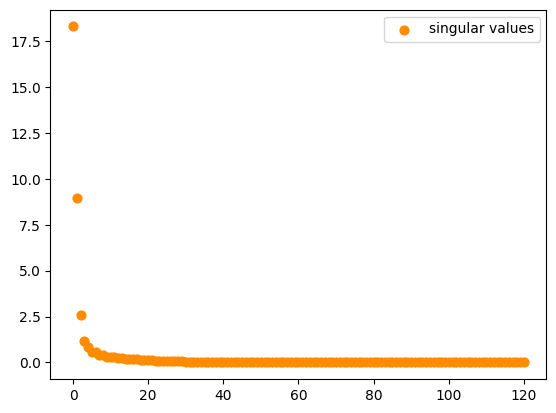

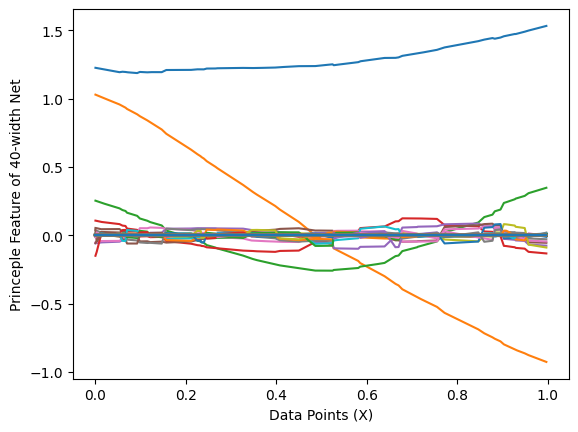

In [12]:
def compute_svd_plot_features(X, y, X_test, y_test, model):
    width = model[0].out_features  # the width is the number of hidden units.
    gradients = np.zeros((width, X.shape[0]))
    num_pts = 0
    gradient_collect, vis_collect = { }, { }
    for x in X:
        y = model(to_torch(x).to(device=device))

        ########################################################################
        # TODO: Complete the following part to run backpropagation. (2 lines)
        # Hint: The same as part (a)
        ########################################################################
        model.zero_grad()
        y.backward()
        ########################################################################

        for n, p in model.named_parameters():
            for w_idx, w_grad in enumerate( p.grad.view(-1).data ):
                if f'{n}.{w_idx}' not in gradient_collect:
                    gradient_collect[ f'{n}.{w_idx}' ] = {'x':[], 'y': []}
                gradient_collect[ f'{n}.{w_idx}' ]['y'].append( w_grad.item() )
                gradient_collect[ f'{n}.{w_idx}' ]['x'].append( x )

    feature_matrix = []
    for w_n in gradient_collect:
        feature_matrix.append( gradient_collect[w_n]['y'] )
    feature_matrix = np.array( feature_matrix ).T

    ############################################################################
    # TODO: Complete the following part to SVD-decompose the feature matrix.
    #       (1 line)
    # Hint: the shape of u, s, vh should be [n, d], [d], and [d, d]
    #       respectively
    ############################################################################
    u, s, vh = np.linalg.svd(feature_matrix, full_matrices=False)
    ############################################################################

    plt.scatter(np.arange(s.shape[0]), s, c='darkorange', s=40.0, label='singular values')
    plt.legend()
    plt.show()

    # Construct more training matrix
    ############################################################################
    # TODO: Complete the following part to compute the pricipal feature
    #       (1 line)
    ############################################################################
    princple_feature = u @ np.diag(s)
    ############################################################################


    for w_idx in range(feature_matrix.shape[1]):
        plt.plot( X, princple_feature.T[w_idx] )

    plt.xlabel('Data Points (X)')
    plt.ylabel(f'Princeple Feature of {width}-width Net')
    plt.show()

for w in widths:
    net = nets_by_size[w]['net']
    print("Width", w)
    compute_svd_plot_features(X, y, X_test, y_test, net)


# (c) Two-layer Network

Augment the jupyter notebook to add a second hidden
layer of the same size as the first hidden layer, fully connected
to the first hidden layer.

Allow the visualization of the features corresponding
to the parameters in both hidden layers, as well as the
"principle features" and the singular values.

----------------------------------------
Two-Layer Width 10
SGD Iteration 10000
SGD Iteration 20000
SGD Iteration 30000
SGD Iteration 40000
SGD Iteration 50000
SGD Iteration 60000
SGD Iteration 70000
SGD Iteration 80000
SGD Iteration 90000
SGD Iteration 100000
SGD Iteration 110000
SGD Iteration 120000
SGD Iteration 130000
SGD Iteration 140000
SGD Iteration 150000
Two-Layer Width 10


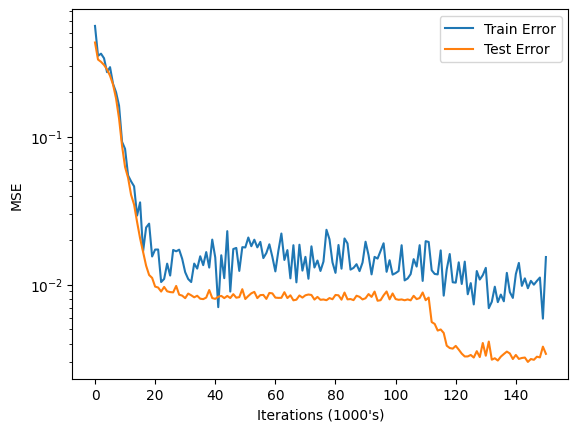

----------------------------------------
Two-Layer Width 20
SGD Iteration 10000
SGD Iteration 20000
SGD Iteration 30000
SGD Iteration 40000
SGD Iteration 50000
SGD Iteration 60000
SGD Iteration 70000
SGD Iteration 80000
SGD Iteration 90000
SGD Iteration 100000
SGD Iteration 110000
SGD Iteration 120000
SGD Iteration 130000
SGD Iteration 140000
SGD Iteration 150000
Two-Layer Width 20


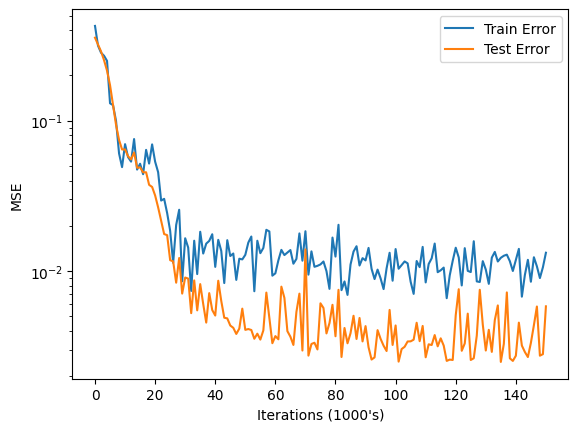

----------------------------------------
Two-Layer Width 40
SGD Iteration 10000
SGD Iteration 20000
SGD Iteration 30000
SGD Iteration 40000
SGD Iteration 50000
SGD Iteration 60000
SGD Iteration 70000
SGD Iteration 80000
SGD Iteration 90000
SGD Iteration 100000
SGD Iteration 110000
SGD Iteration 120000
SGD Iteration 130000
SGD Iteration 140000
SGD Iteration 150000
Two-Layer Width 40


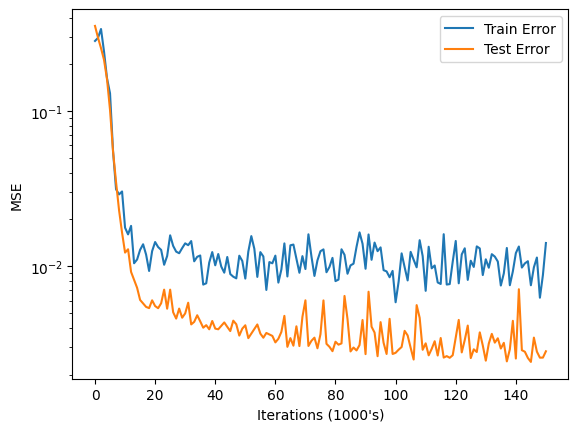

=== Two-Layer Network Width 10 ===


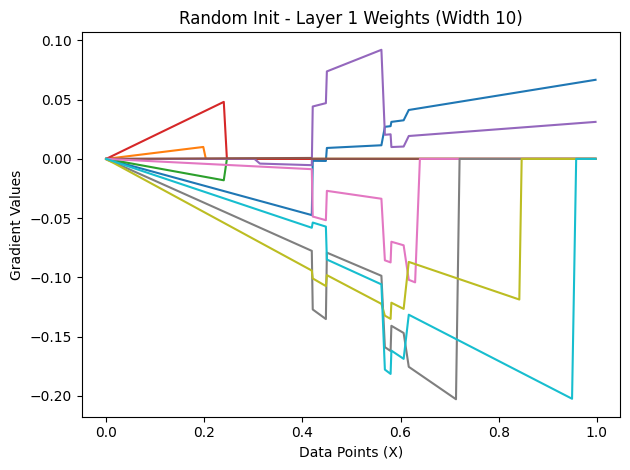

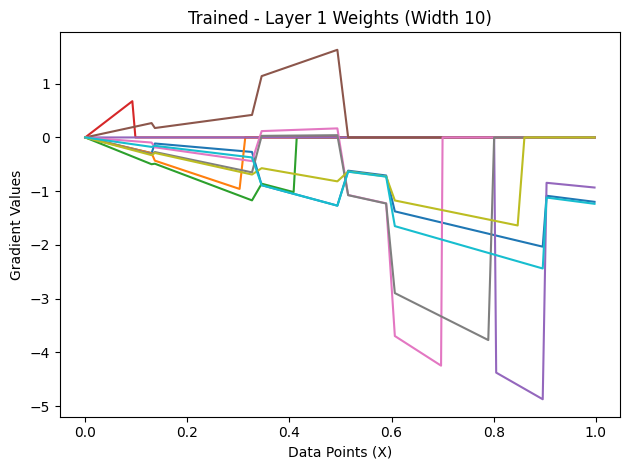

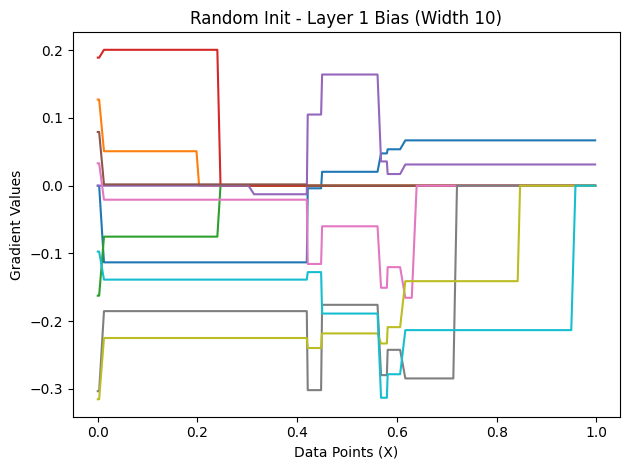

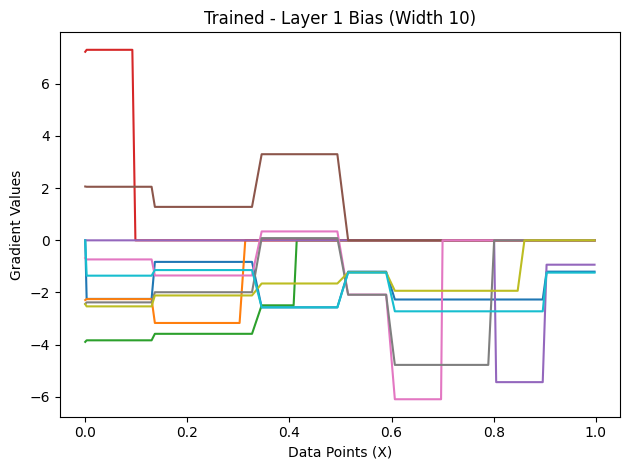

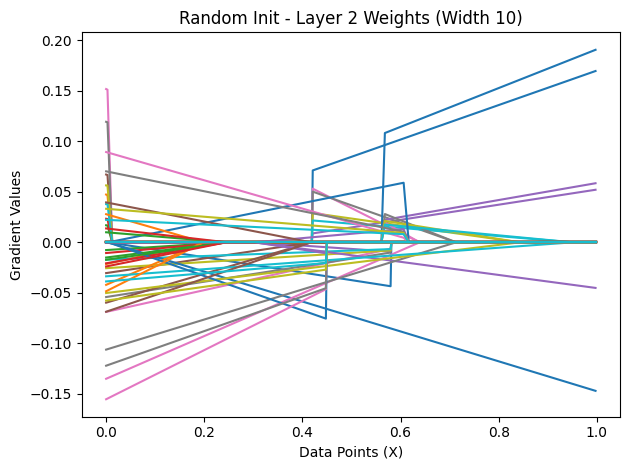

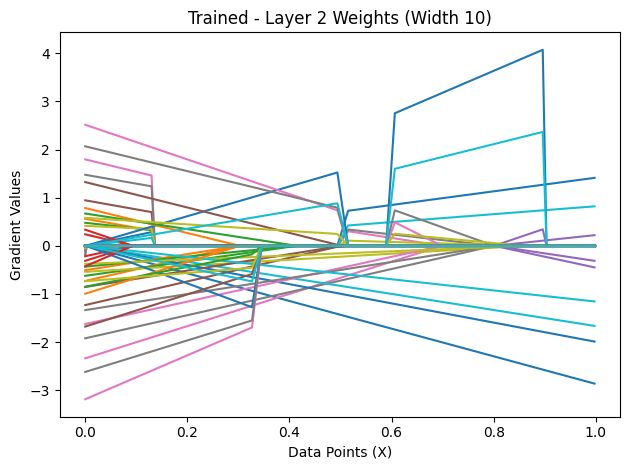

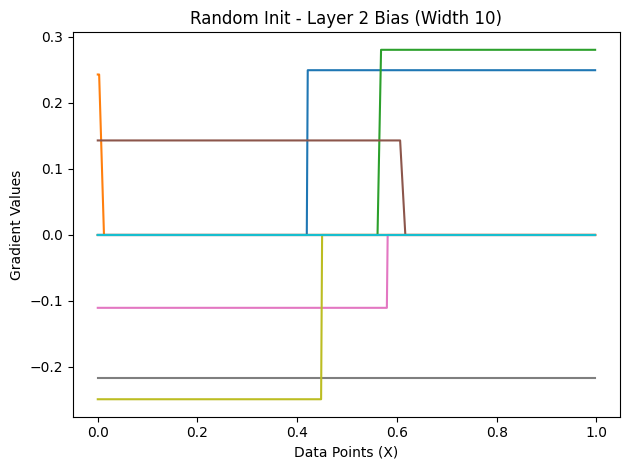

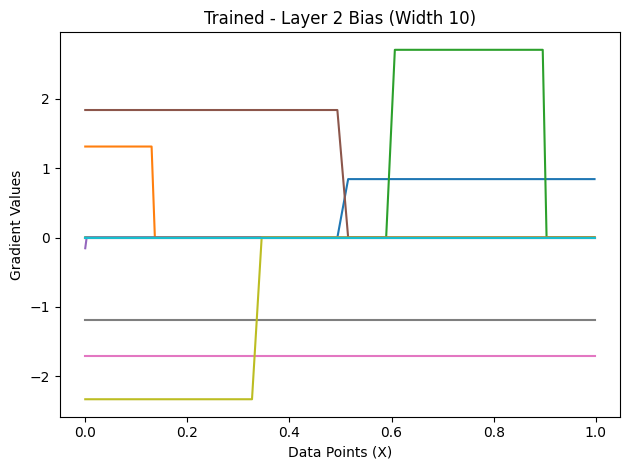

=== Two-Layer Network Width 20 ===


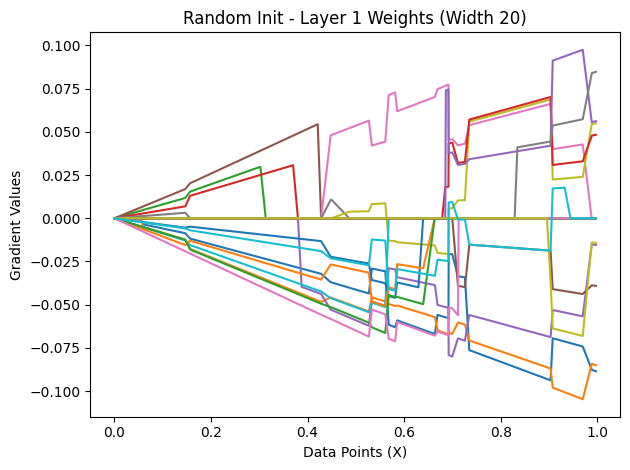

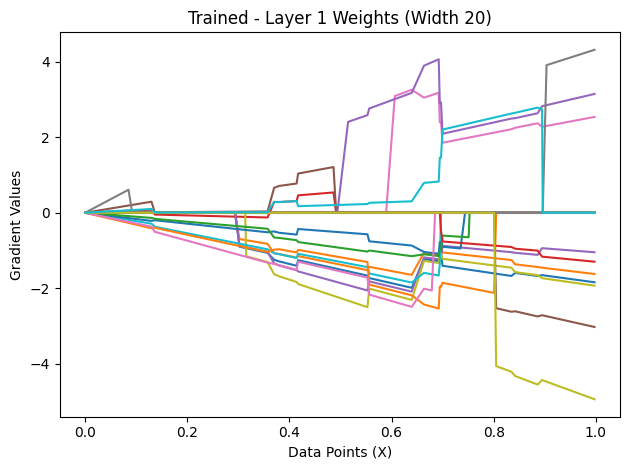

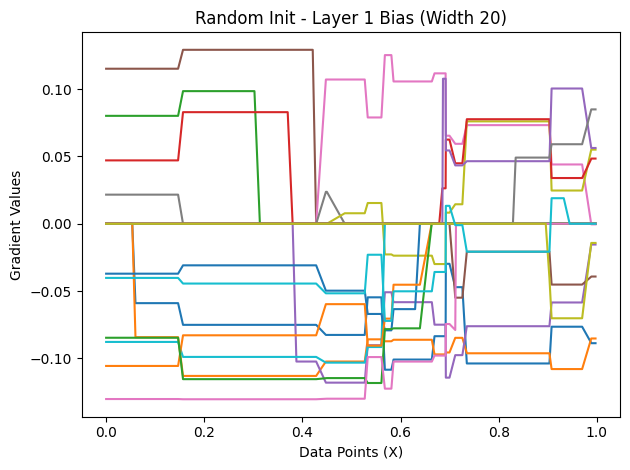

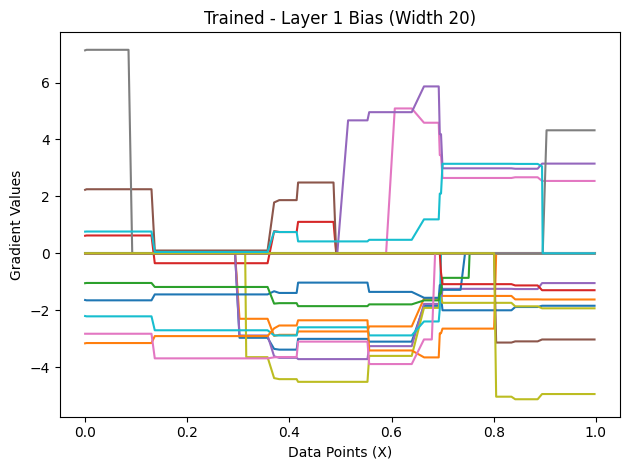

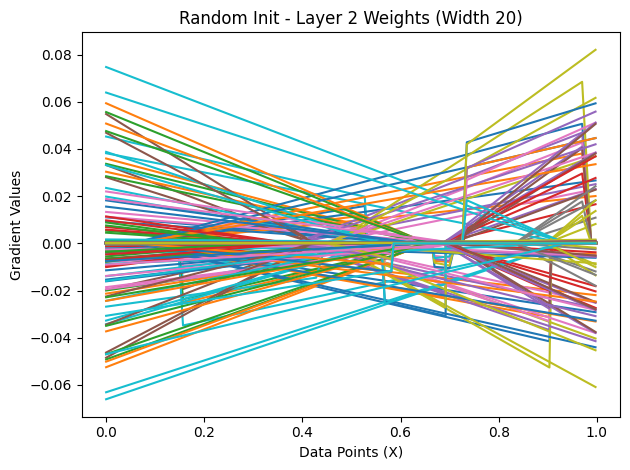

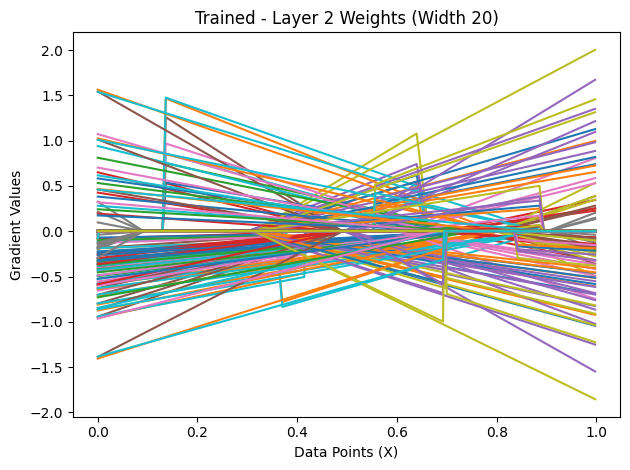

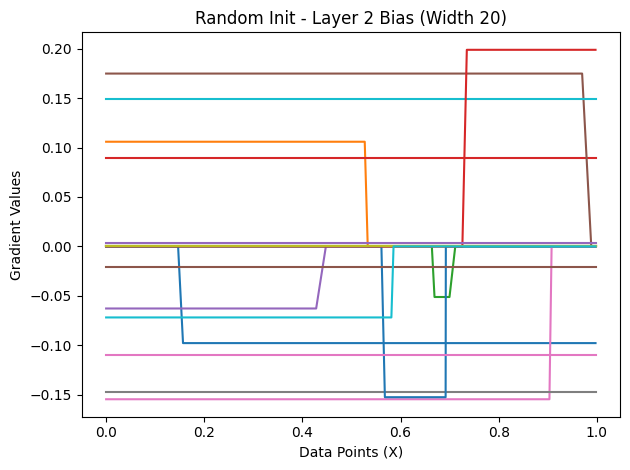

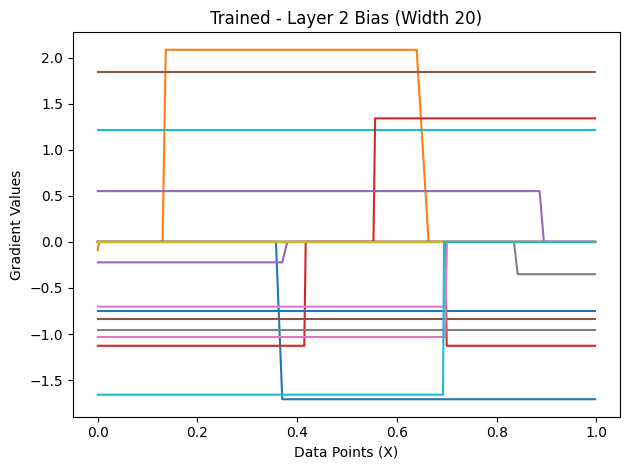

=== Two-Layer Network Width 40 ===


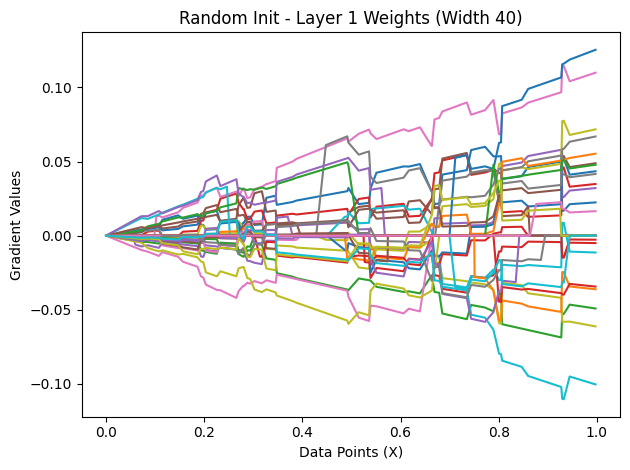

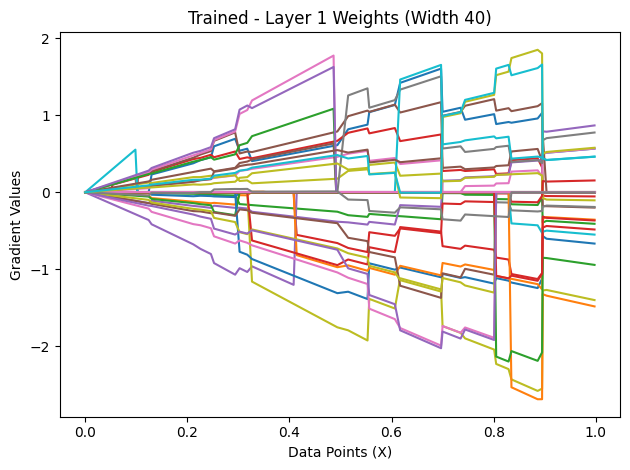

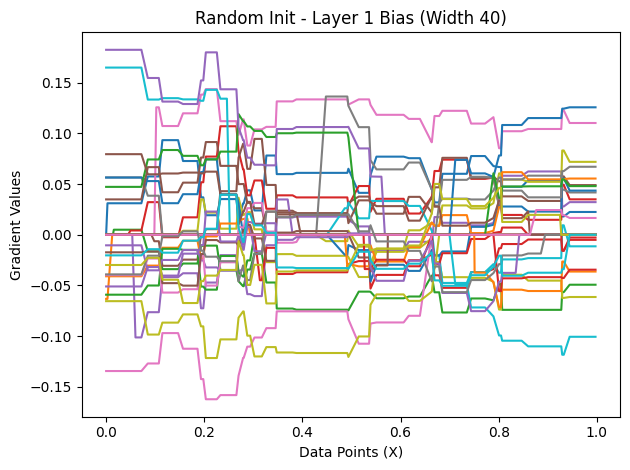

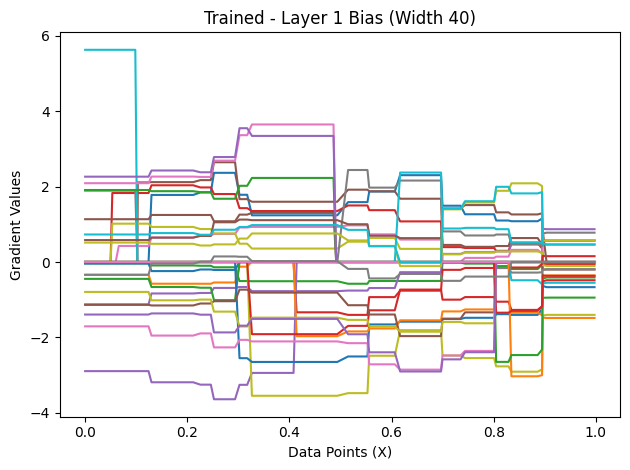

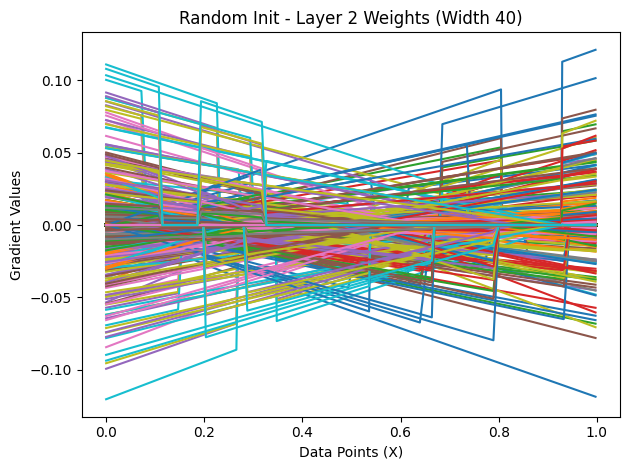

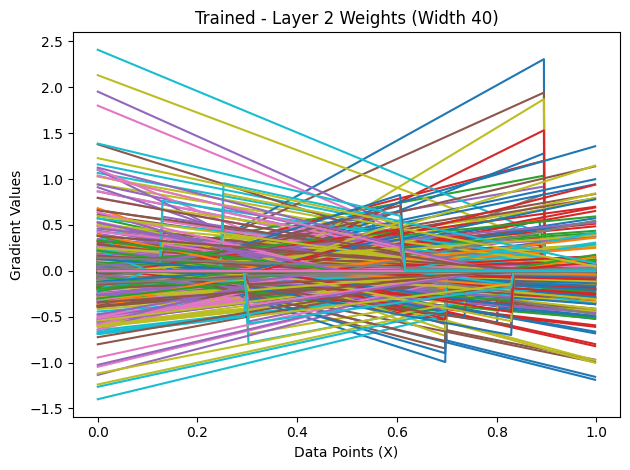

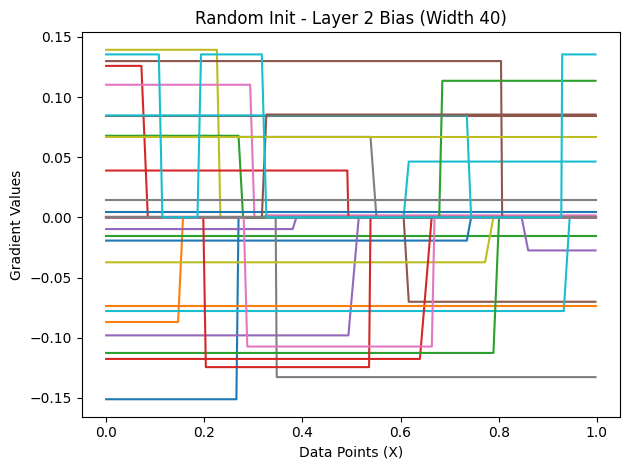

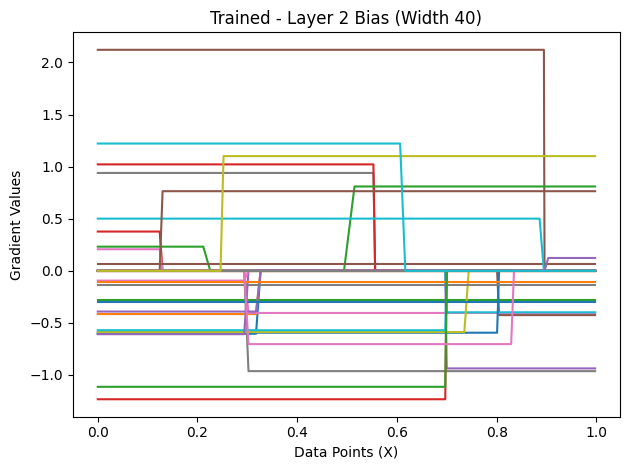

=== Two-Layer Network Width 10 - Random Initialization ===


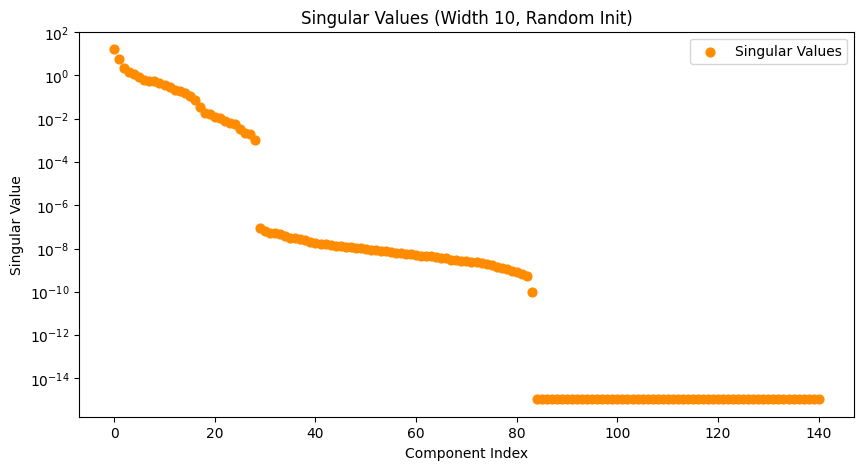

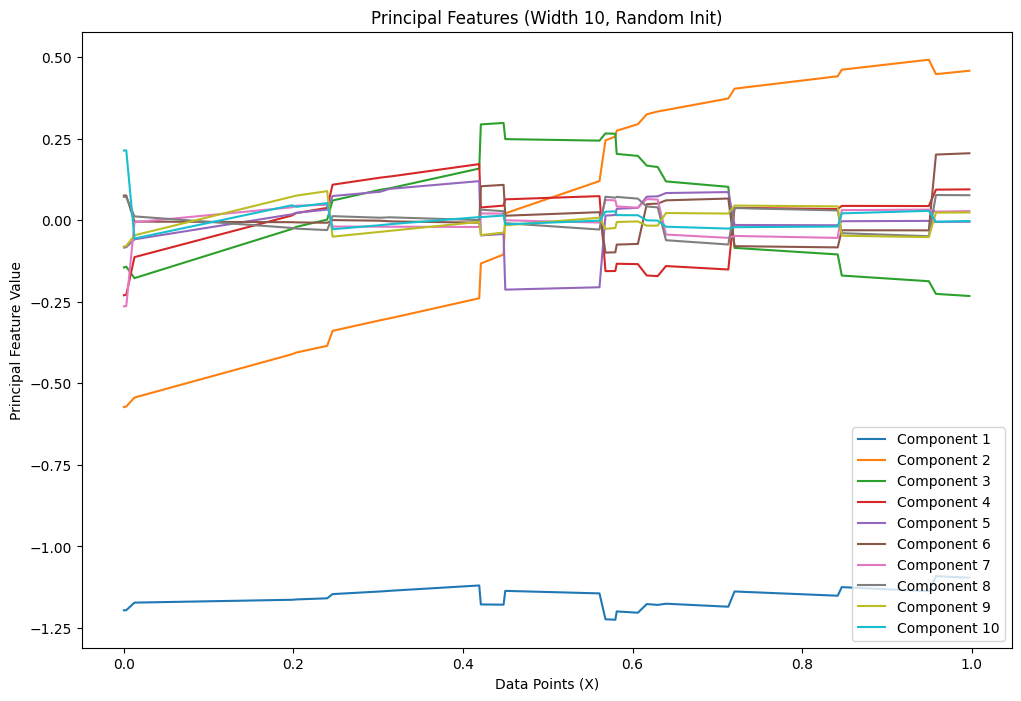

=== Two-Layer Network Width 10 - After Training ===


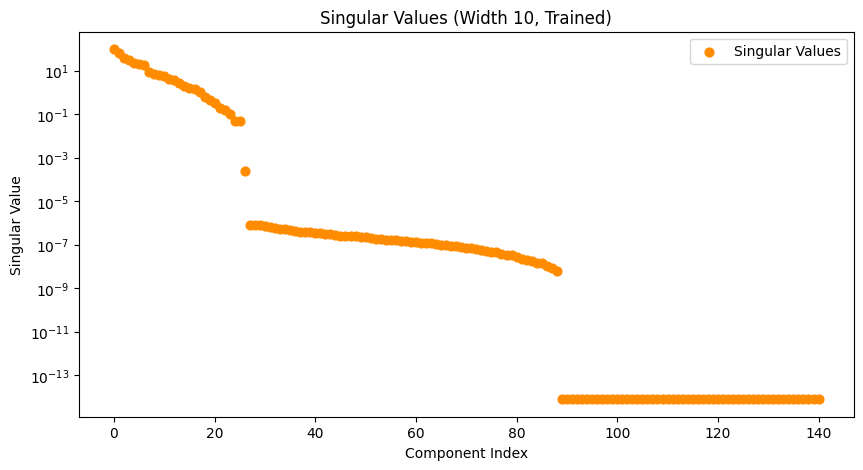

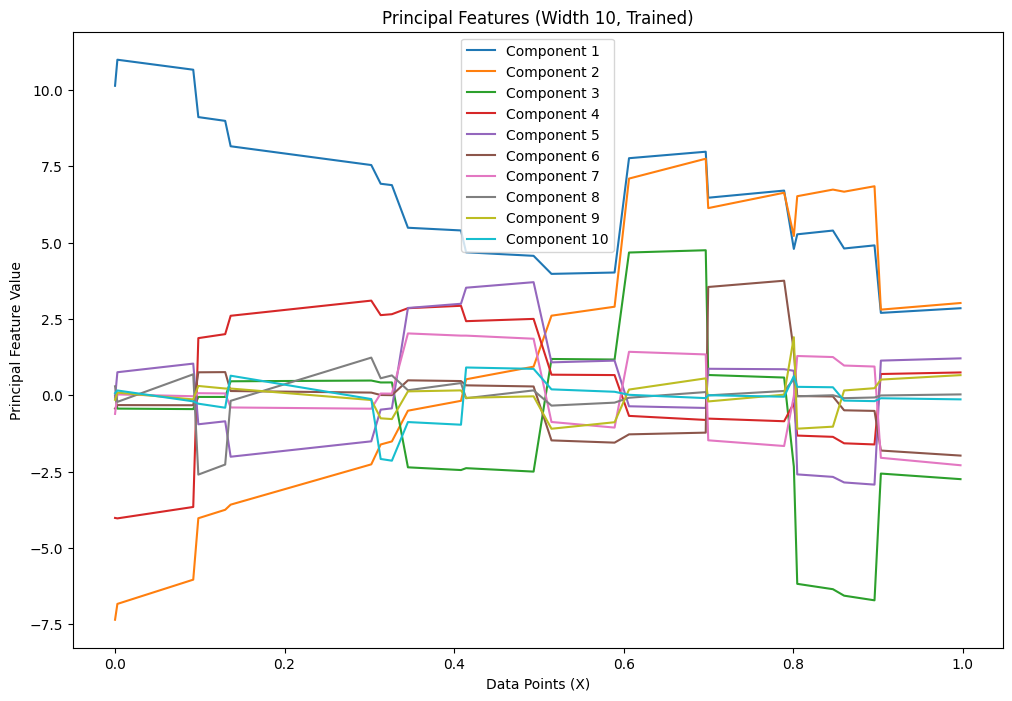

=== Two-Layer Network Width 20 - Random Initialization ===


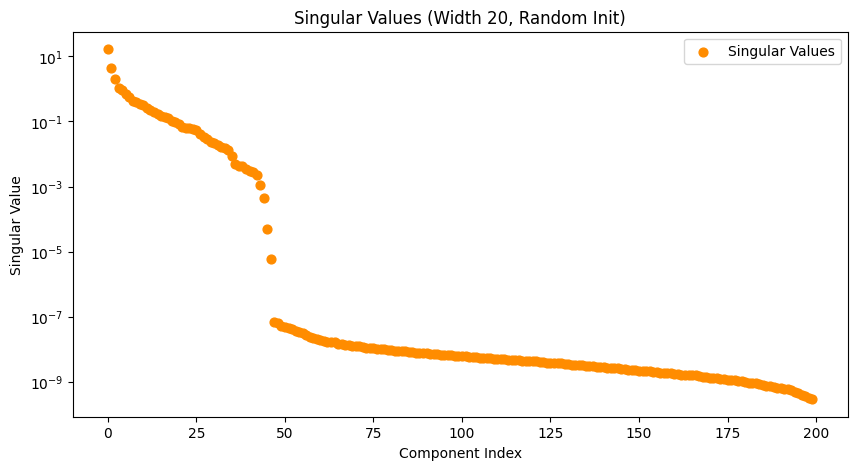

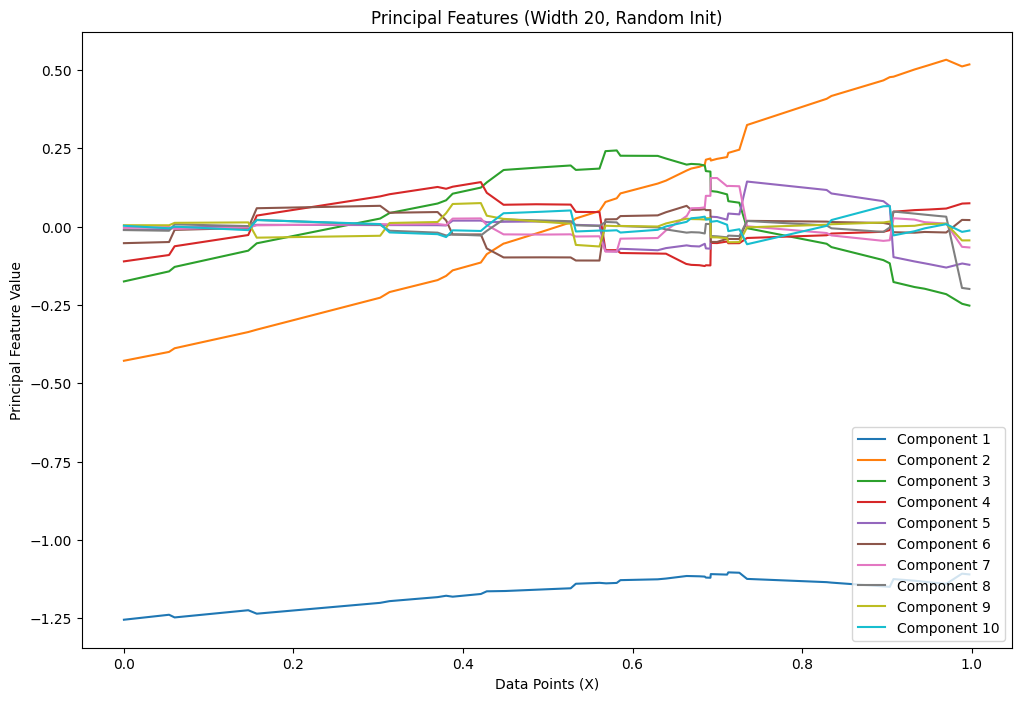

=== Two-Layer Network Width 20 - After Training ===


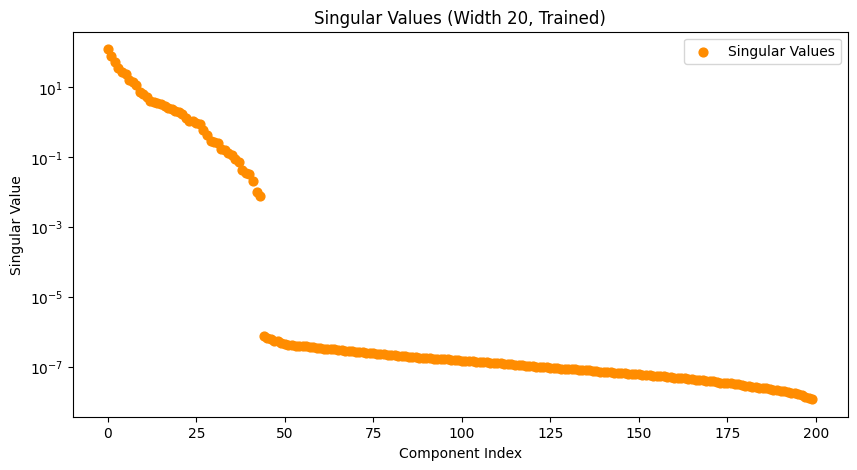

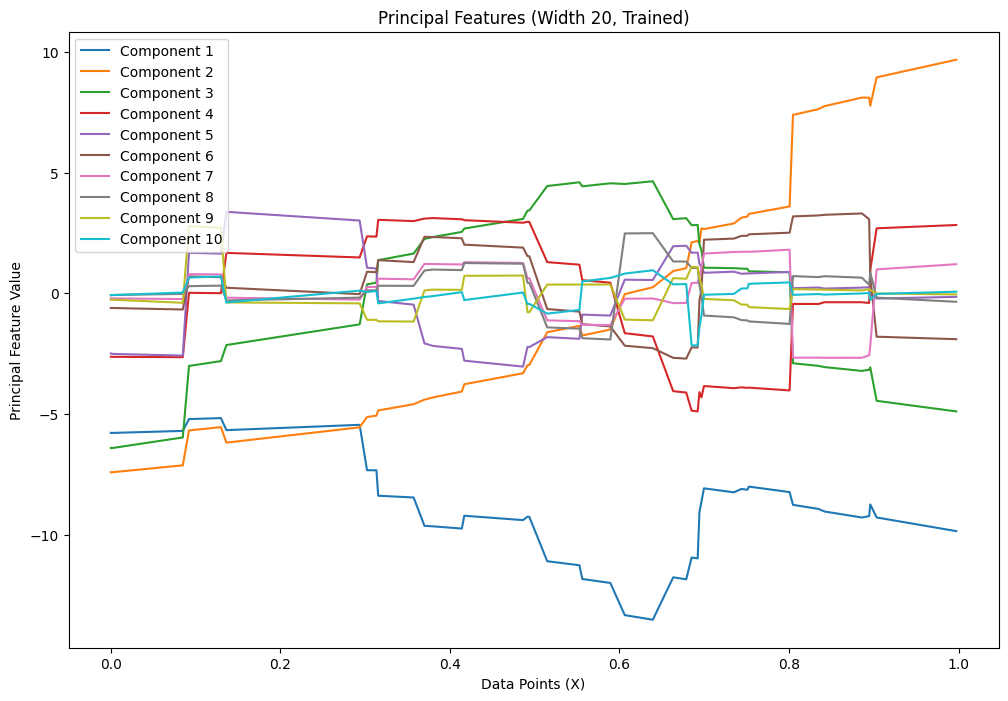

=== Two-Layer Network Width 40 - Random Initialization ===


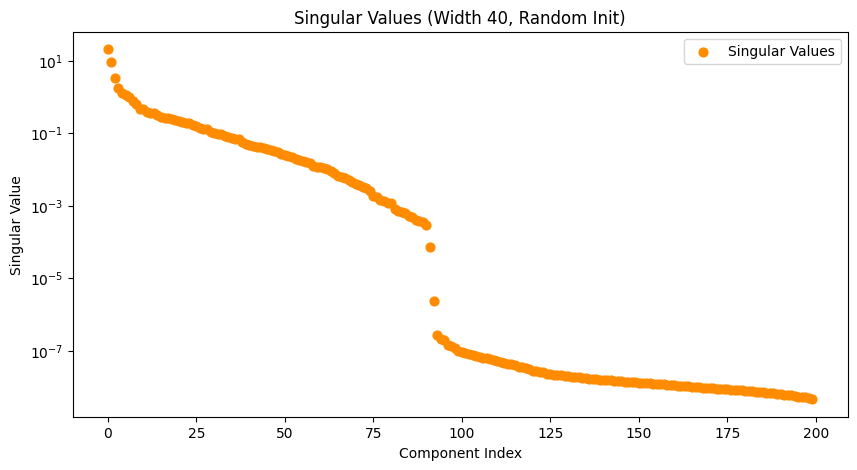

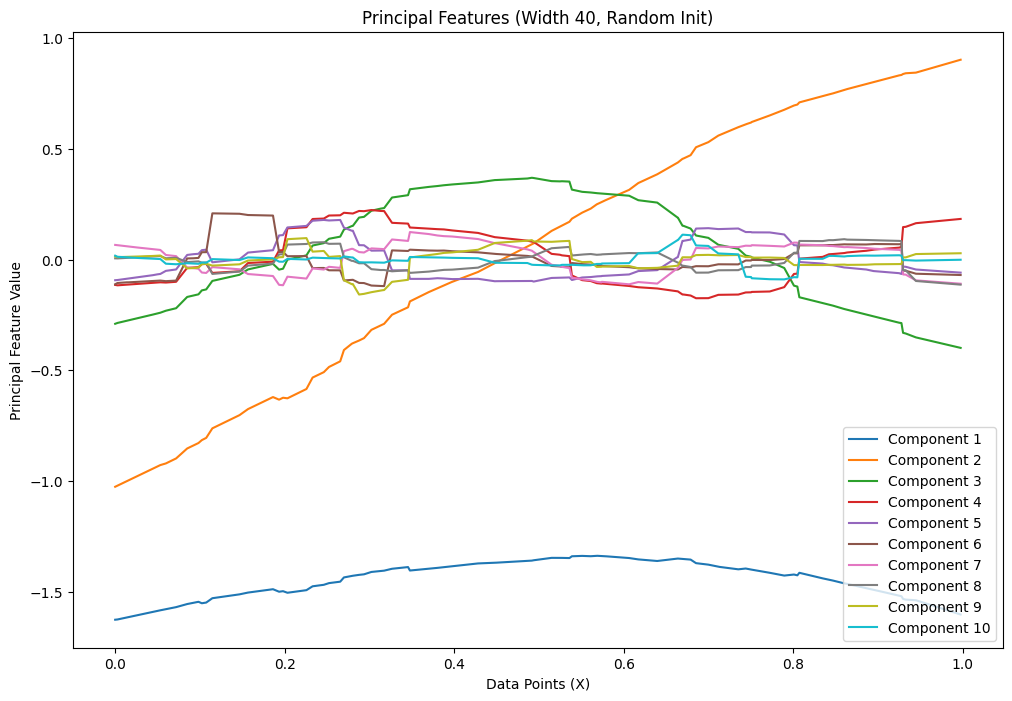

=== Two-Layer Network Width 40 - After Training ===


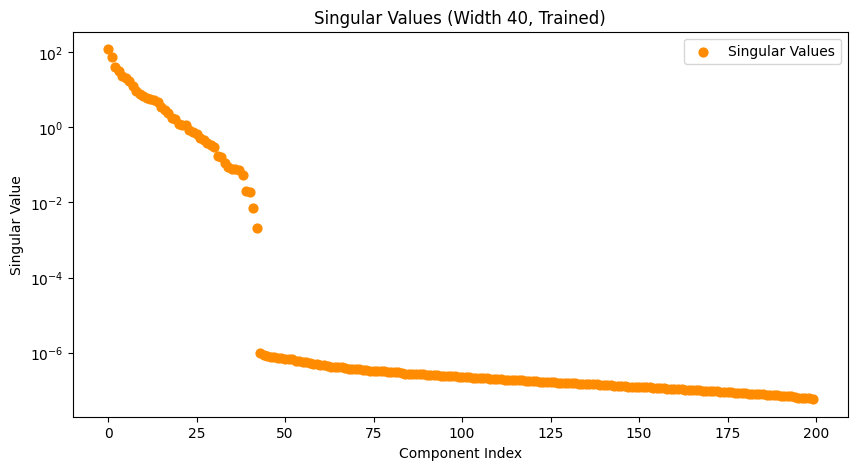

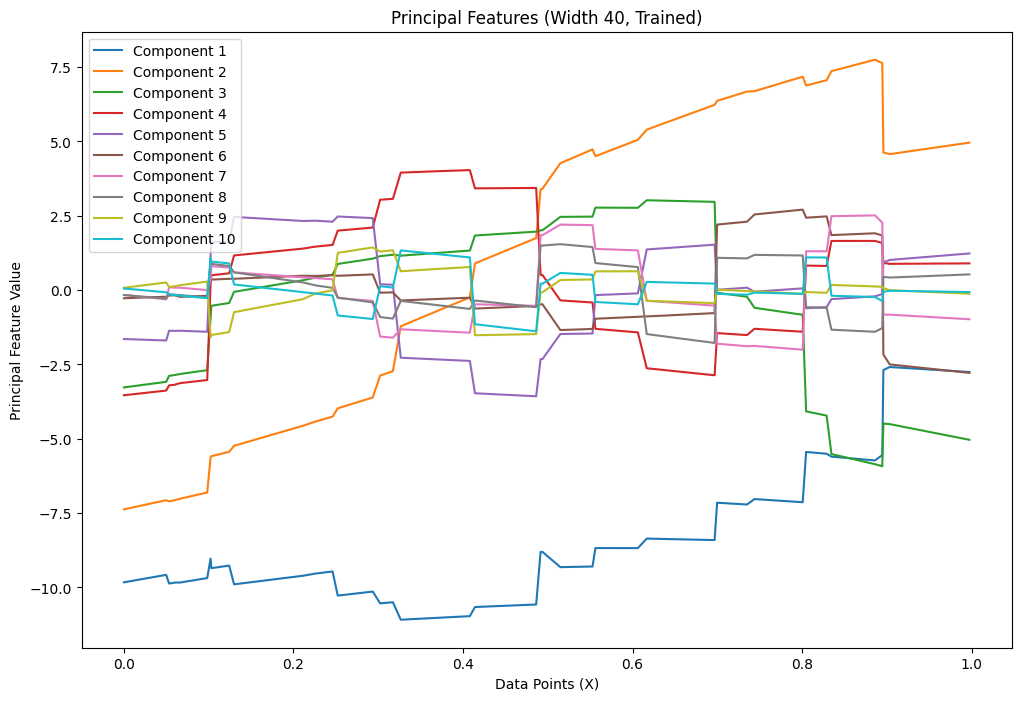

In [13]:
################################################################################
# (YOUR CODE HERE)
# Hint: You can reuse most of the code from above. You should change the network
# definition and visualization function 'backward_and_plot_grad' such that an
# additional hidden layer is added.
################################################################################
# Define two-layer neural networks
nets_two_layer = {}

for width in widths:
    # Define 2-hidden layer neural network
    net = nn.Sequential(
        nn.Linear(1, width),      # First hidden layer
        nn.ReLU(),
        nn.Linear(width, width),  # Second hidden layer
        nn.ReLU(),
        nn.Linear(width, 1)       # Output layer
    )

    # Get all trainable parameters
    weights_all = list(net.parameters())

    # Adjust first layer biases to position ReLU elbows in [0,1] range
    elbows = np.sort(np.random.rand(width))
    new_biases_1 = -elbows * to_numpy(weights_all[0]).ravel()
    weights_all[1].data = to_torch(new_biases_1)

    # Use Xavier initialization for second layer weights and biases
    torch.nn.init.xavier_uniform_(weights_all[2])
    torch.nn.init.normal_(weights_all[3], mean=0, std=0.1)

    # Create optimizer with appropriate learning rate for deeper network
    lr_all = 0.01
    opt_all = torch.optim.SGD(params=weights_all, lr=lr_all)

    # Save initial state
    initial_weights = copy.deepcopy(net.state_dict())

    nets_two_layer[width] = {
        'net': net,
        'opt_all': opt_all,
        'init': initial_weights
    }

# Move networks to device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
for width, net_dict in nets_two_layer.items():
    net_dict['net'].to(device=device)

# Train two-layer networks
n_steps = 150000
save_every = 1000

for w in widths:
    print("-"*40)
    print("Two-Layer Width", w)

    # Create new network instance and load initial weights
    new_net = nn.Sequential(
        nn.Linear(1, w),
        nn.ReLU(),
        nn.Linear(w, w),
        nn.ReLU(),
        nn.Linear(w, 1)
    )
    new_net.load_state_dict(nets_two_layer[w]['net'].state_dict().copy())
    new_net.to(device=device)

    # Create optimizer
    opt_all = torch.optim.SGD(params=new_net.parameters(), lr=0.01)
    initial_weights = nets_two_layer[w]['init']

    # Train network
    history_all = train_network(X, y, X_test, y_test,
                               new_net, optim=opt_all,
                               n_steps=n_steps, save_every=save_every,
                               initial_weights=initial_weights,
                               verbose=False, device=device)

    # Save training results
    nets_two_layer[w]['trained_net'] = new_net
    nets_two_layer[w]['hist_all'] = history_all

    print("Two-Layer Width", w)
    plot_test_train_errors(history_all)

# Enhanced gradient visualization function supporting multi-layer networks
def backward_and_plot_grad_enhanced(X, model, layer_patterns=None, title='', legend=False):
    """
    Enhanced gradient visualization function supporting multi-layer networks
    layer_patterns: List of layer patterns to visualize, e.g., ['0.', '2.'] for first and third layers
    """
    if layer_patterns is None:
        layer_patterns = ['all']

    gradient_collect = {}

    for x in X:
        y_pred = model(to_torch(x).to(device=device))

        # Clear gradients and run backpropagation
        model.zero_grad()
        y_pred.backward()

        # Collect gradients
        for name, param in model.named_parameters():
            if param.grad is not None:
                # Check if parameter is in specified layers
                include_param = 'all' in layer_patterns
                if not include_param:
                    for pattern in layer_patterns:
                        if name.startswith(pattern):
                            include_param = True
                            break

                if include_param:
                    for idx, grad_val in enumerate(param.grad.view(-1).data):
                        param_name = f'{name}.{idx}'
                        if param_name not in gradient_collect:
                            gradient_collect[param_name] = {'x': [], 'y': []}
                        gradient_collect[param_name]['y'].append(grad_val.item())
                        gradient_collect[param_name]['x'].append(x)

    # Plot gradients
    for param_name, data in gradient_collect.items():
        plt.plot(data['x'], data['y'], label=param_name)

    plt.xlabel('Data Points (X)')
    plt.ylabel('Gradient Values')
    if legend:
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title(title)
    plt.tight_layout()
    plt.show()

# Visualize gradients for two-layer networks
for width in widths:
    net = nets_two_layer[width]['net']
    trained_net = nets_two_layer[width]['trained_net']

    print(f"=== Two-Layer Network Width {width} ===")

    # First layer weights and biases
    backward_and_plot_grad_enhanced(X, net, ['0.weight'], f'Random Init - Layer 1 Weights (Width {width})')
    backward_and_plot_grad_enhanced(X, trained_net, ['0.weight'], f'Trained - Layer 1 Weights (Width {width})')
    backward_and_plot_grad_enhanced(X, net, ['0.bias'], f'Random Init - Layer 1 Bias (Width {width})')
    backward_and_plot_grad_enhanced(X, trained_net, ['0.bias'], f'Trained - Layer 1 Bias (Width {width})')

    # Second layer weights and biases
    backward_and_plot_grad_enhanced(X, net, ['2.weight'], f'Random Init - Layer 2 Weights (Width {width})')
    backward_and_plot_grad_enhanced(X, trained_net, ['2.weight'], f'Trained - Layer 2 Weights (Width {width})')
    backward_and_plot_grad_enhanced(X, net, ['2.bias'], f'Random Init - Layer 2 Bias (Width {width})')
    backward_and_plot_grad_enhanced(X, trained_net, ['2.bias'], f'Trained - Layer 2 Bias (Width {width})')

# Enhanced SVD analysis function supporting multi-layer networks
def compute_svd_plot_features_enhanced(X, y, X_test, y_test, model, title_suffix=''):
    """
    Enhanced SVD analysis function supporting multi-layer networks
    """
    gradient_collect = {}

    for x in X:
        y_pred = model(to_torch(x).to(device=device))

        # Clear gradients and run backpropagation
        model.zero_grad()
        y_pred.backward()

        # Collect gradients from all parameters
        for name, param in model.named_parameters():
            if param.grad is not None:
                for idx, grad_val in enumerate(param.grad.view(-1).data):
                    param_name = f'{name}.{idx}'
                    if param_name not in gradient_collect:
                        gradient_collect[param_name] = {'x': [], 'y': []}
                    gradient_collect[param_name]['y'].append(grad_val.item())
                    gradient_collect[param_name]['x'].append(x)

    # Build feature matrix
    feature_matrix = []
    for param_name in gradient_collect:
        feature_matrix.append(gradient_collect[param_name]['y'])

    feature_matrix = np.array(feature_matrix).T

    # Perform SVD decomposition
    u, s, vh = np.linalg.svd(feature_matrix, full_matrices=False)

    # Plot singular values
    plt.figure(figsize=(10, 5))
    plt.scatter(np.arange(s.shape[0]), s, c='darkorange', s=40.0, label='Singular Values')
    plt.xlabel('Component Index')
    plt.ylabel('Singular Value')
    plt.title(f'Singular Values {title_suffix}')
    plt.yscale('log')
    plt.legend()
    plt.show()

    # Compute principal features
    principal_features = u @ np.diag(s)

    # Plot principal features
    plt.figure(figsize=(12, 8))
    n_components_to_plot = min(10, feature_matrix.shape[1])
    for idx in range(n_components_to_plot):
        plt.plot(X, principal_features[:, idx], label=f'Component {idx+1}')

    plt.xlabel('Data Points (X)')
    plt.ylabel('Principal Feature Value')
    plt.title(f'Principal Features {title_suffix}')
    plt.legend()
    plt.show()

# Perform SVD analysis on two-layer networks
for w in widths:
    net = nets_two_layer[w]['net']
    trained_net = nets_two_layer[w]['trained_net']

    print(f"=== Two-Layer Network Width {w} - Random Initialization ===")
    compute_svd_plot_features_enhanced(X, y, X_test, y_test, net, f'(Width {w}, Random Init)')

    print(f"=== Two-Layer Network Width {w} - After Training ===")
    compute_svd_plot_features_enhanced(X, y, X_test, y_test, trained_net, f'(Width {w}, Trained)')
